## Linear algebra

MATLAB was born as a matrix laboratory. This notebook solves systems, factors matrices and puts the eigenvalue and singular value decompositions to work.

### Solving $Ax = b$

The backslash operator picks a method from the matrix's structure (triangular, symmetric positive definite, general) and warns when the matrix is close to singular. `cond` measures how much the solution can amplify errors in $b$.

In [ ]:
A = [4 -2 1; -2 4 -2; 1 -2 4];
b = [11; -16; 17];
x = A \ b
residual = norm(A*x - b)
kappa = cond(A)


x =

     1
    -2
     3




residual =

     0


kappa =

    4.5292



### Factorizations

LU with partial pivoting ($PA = LU$), QR ($A = QR$ with $Q$ orthogonal) and Cholesky ($A = R^T R$ for a symmetric positive definite $A$).

In [ ]:
[L, U, P] = lu(A);
lu_error = norm(P*A - L*U)
[Q, R] = qr(A);
orthogonality = norm(Q'*Q - eye(3))
Rc = chol(A)
chol_error = norm(Rc'*Rc - A)


lu_error =

     0


orthogonality =

   4.5092e-16


Rc =

    2.0000   -1.0000    0.5000
         0    1.7321   -0.8660
         0         0    1.7321


chol_error =

   4.4409e-16



### Eigenmodes of a chain of springs

Five equal masses joined by equal springs, fixed at both ends. The squared frequencies of the normal modes are the eigenvalues of the stiffness matrix $K$, and each eigenvector is a mode shape: how far each mass moves.


frequencies =

    0.5176    1.0000    1.4142    1.7321    1.9319



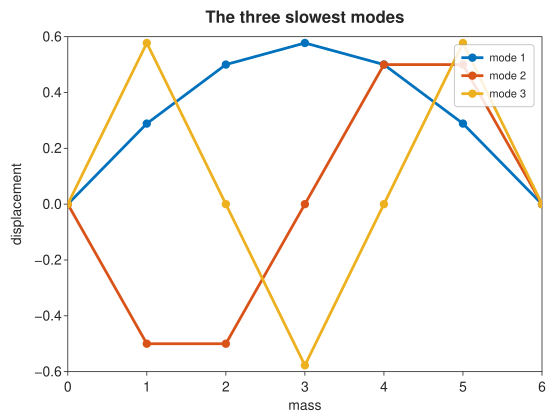

In [ ]:
figure
n = 5;
K = 2*eye(n) - diag(ones(n-1, 1), 1) - diag(ones(n-1, 1), -1);
[V, D] = eig(K);
frequencies = sqrt(diag(D))'
plot(0:n+1, [zeros(1, 3); V(:, 1:3); zeros(1, 3)], 'o-', 'LineWidth', 1.5)
legend('mode 1', 'mode 2', 'mode 3')
xlabel('mass'), ylabel('displacement')
title('The three slowest modes')

### Least squares

More equations than unknowns: fit $y \approx c_1 + c_2 t + c_3 t^2$ to noisy data. Backslash on a tall matrix gives the least-squares solution, the same as `pinv`, but computed stably by QR.

In [ ]:
rng(2);
t = linspace(0, 4, 30)';
y = 1 + 0.5*t - 0.3*t.^2 + 0.15*randn(30, 1);
M = [ones(30, 1), t, t.^2];
coef = M \ y
same_by_pinv = norm(coef - pinv(M)*y) < 1e-12
rms_residual = norm(M*coef - y) / sqrt(30)


coef =

    0.8860
    0.5886
   -0.3240




same_by_pinv =

  logical

   1


rms_residual =

    0.1240



### Low-rank approximation by the SVD

The singular value decomposition $A = U \Sigma V^T$ gives the best rank-$k$ approximation of a matrix: keep the $k$ largest singular values. An image is a matrix, so a few singular values already hold most of it.

rank 1 keeps 76.07% of the energy
rank 3 keeps 91.54% of the energy
rank 10 keeps 98.51% of the energy


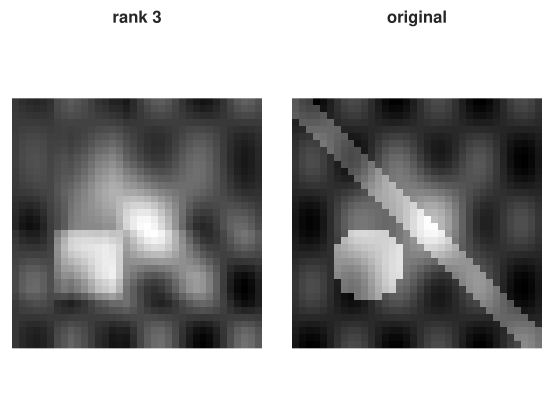

In [ ]:
figure
[gx, gy] = meshgrid(linspace(-3, 3, 36));
img = exp(-(gx.^2 + gy.^2)/2) + 0.8*((gx + 1.2).^2 + (gy - 1).^2 < 0.8) + 0.5*(abs(gx - gy) < 0.4) + 0.3*sin(3*gx).*cos(2*gy);
[Us, S, Vs] = svd(img);
sv = diag(S);
ranks = [1 3 10];
k = 3;
subplot(1, 2, 1), imagesc(Us(:, 1:k) * S(1:k, 1:k) * Vs(:, 1:k)'), axis equal off, title('rank 3')
subplot(1, 2, 2), imagesc(img), axis equal off, title('original')
colormap(gray)
energy = 100 * cumsum(sv.^2) / sum(sv.^2);
fprintf('rank %d keeps %.2f%% of the energy\n', [ranks; energy(ranks)'])

*Topics after examples in MatRust-Studio (MIT license); the code here is Sagebrush's own.*